# Annular Boussinesq — AWFNO JCP one-run numerical study

*   List item
*   List item



Google Colab GPU: select **Runtime → Run all**. This executes two suites sequentially and stores checkpoints, plots, and results on Google Drive so completed trials can be resumed. During the original stage, each training-set size is now trained, evaluated and written to CSV/JSON *before* proceeding to the next size. Live subprocess training logs are streamed into Colab.

1. **Original sample-size sweep:** TB-AWFNO, AWFNO, WFNO, full-trajectory FNO at N = 25, 50, 100, 200, 400.
2. **Controlled reviewer suites (three seeds):** LGL / LLG / GLL orderings, LLL / GGG component ablations, window K = 1, 10, 30, radius r = 1, 2, 3, Fourier modes (8,12)/(16,24)/(24,32), parameter-matched WFNO and temporal-basis head.

The observable is the scalar HyTeG annulus field `c_grid`, not velocity or pressure. This notebook does **not** implement modern F-FNO, U-Net, CNO, or U-NO baselines. The controlled study has 51 fits plus up to 20 original fits, so it may require more than one Colab session. Re-executing skips saved completed trials.

In [1]:
#@title 1. Mount Drive and check annulus data
from google.colab import drive
from pathlib import Path
import torch, os, sys, subprocess
drive.mount('/content/gdrive')
DATASET=Path('/content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt')
OUTPUT_ROOT=Path('/content/gdrive/MyDrive/anus/Boussinesq_JCP')
OUTPUT_ROOT.mkdir(parents=True,exist_ok=True)
assert DATASET.is_file(), f"Missing dataset: {DATASET}"
assert torch.cuda.is_available(), "Set Google Colab runtime to GPU."
print('GPU:',torch.cuda.get_device_name(0))
print('Data:',DATASET,'size GiB:',round(DATASET.stat().st_size/1024**3,3))
print('Outputs:',OUTPUT_ROOT)

Mounted at /content/gdrive
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Data: /content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt size GiB: 3.098
Outputs: /content/gdrive/MyDrive/anus/Boussinesq_JCP


In [2]:
#@title 2. Install the reference full-trajectory FNO dependency
subprocess.check_call([sys.executable,'-m','pip','-q','install','neuraloperator==2.0.0'])
import importlib.metadata
print('NeuralOperator:',importlib.metadata.version('neuraloperator'))

NeuralOperator: 2.0.0


## Experiment driver

The full experiment implementation is available as [readable Python source](annulus2d_jcp_experiments.py) in this repository. The next cell downloads that file directly from GitHub and checks its SHA-256 before executing it. There is no embedded or obfuscated code.


In [3]:
#@title 3. Load the readable experiment driver from GitHub
from pathlib import Path
from urllib.request import urlopen
import hashlib

# Full, readable implementation:
# https://github.com/dimigourz/AWFNO/blob/main/Boussinesq2D/annulus2d_jcp_experiments.py
SOURCE_URL = (
    "https://raw.githubusercontent.com/dimigourz/AWFNO/main/"
    "Boussinesq2D/annulus2d_jcp_experiments.py"
)
EXPECTED_SHA256 = "a4d78c78bda2703e408ae90ed501dd56334294c9082c086ab2516df6a7acc883"
DRIVER = Path("/content/annulus2d_jcp_experiments.py")

with urlopen(SOURCE_URL, timeout=60) as response:
    source = response.read()
actual_sha256 = hashlib.sha256(source).hexdigest()
if actual_sha256 != EXPECTED_SHA256:
    raise RuntimeError(
        f"Experiment source checksum differs from validated version: {actual_sha256}. "
        "Inspect the GitHub source and deliberately update EXPECTED_SHA256 before continuing."
    )

DRIVER.write_bytes(source)
print(f"Experiment script ready: {DRIVER} ({len(source):,} bytes)")

Experiment script ready: /content/annulus2d_jcp_experiments.py (103,262 bytes)


In [4]:
#@title 4. Configuration — full original + controlled runs
RUN_ORIGINAL = True #@param {type:'boolean'}
RUN_CONTROLLED = True #@param {type:'boolean'}
CONTROLLED_SUITE = 'all' #@param ['all','ordering','components','window','radius','modes','matched','temporal_basis']
SEEDS = '1234,1235,1236' #@param {type:'string'}
SAMPLE_SIZES = '25,50,100,200,400' #@param {type:'string'}
N_TRAIN_CONTROLLED = 400 #@param {type:'integer'}
EPOCHS = 150 #@param {type:'integer'}
BATCH_SIZE = 32 #@param {type:'integer'}
FORCE_RETRAIN = False #@param {type:'boolean'}
WINDOW_SWEEP = '1,10,30,50'
RADIUS_SWEEP = '1,2,3'
assert RUN_ORIGINAL or RUN_CONTROLLED
print('Original:',RUN_ORIGINAL,'Controlled:',RUN_CONTROLLED,'Seeds:',SEEDS)

Original: True Controlled: True Seeds: 1234,1235,1236


\nSTART: original | driver=/content/annulus2d_jcp_experiments.py | output=/content/gdrive/MyDrive/anus/Boussinesq_JCP
Live training output will appear below. Full log: /content/gdrive/MyDrive/anus/Boussinesq_JCP/original_stdout.log
Using device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition

Experiment
----------
name             : annulus2d_awfno_sample_sweep
data path        : /content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt
output root      : /content/gdrive/MyDrive/anus/Boussinesq_JCP
cache root       : /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2
device           : cuda
ALL_SAMPLE_SIZES : [25, 50, 100, 200, 400]
SAMPLE_SIZES run : [25, 50, 100, 200, 400]
N_TRAIN_POOL     : 400
N_VAL/N_TEST     : 30 70
EPOCHS           : 150
[ORIGINAL] Opening annulus dataset (3.10 GiB); loading data into CPU memory.

Loaded annulus data
-------------------
file: /content/gdrive/MyDrive/

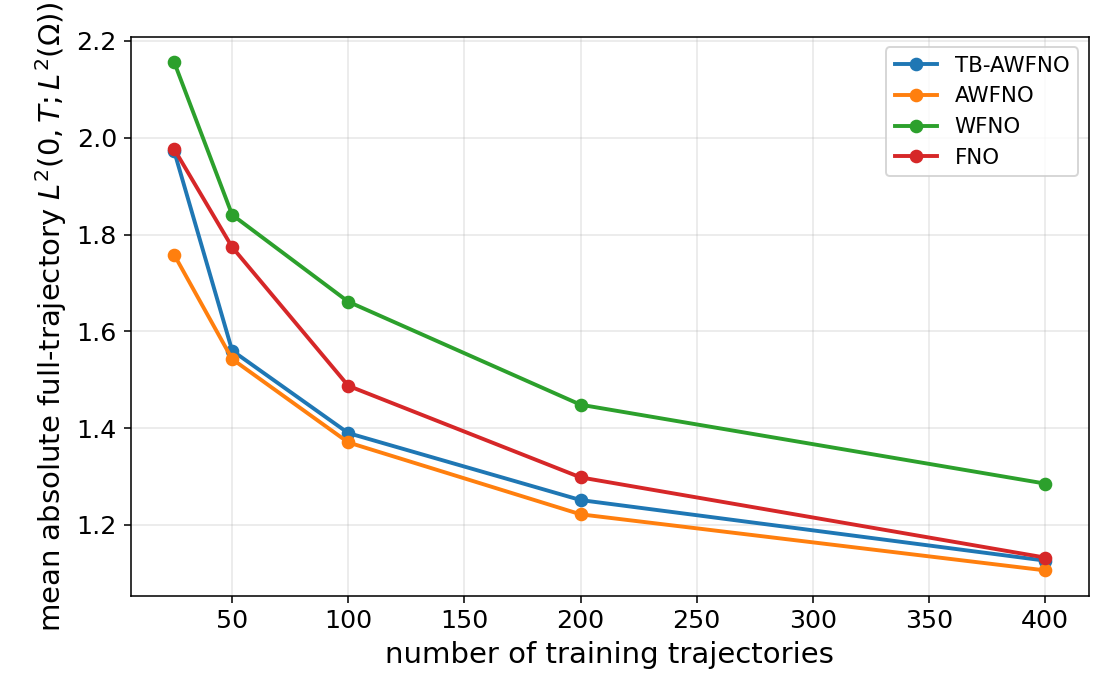

Plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/sample_size_sweep_abs_final_L2_common_test_run_25-50-100-200-400.png


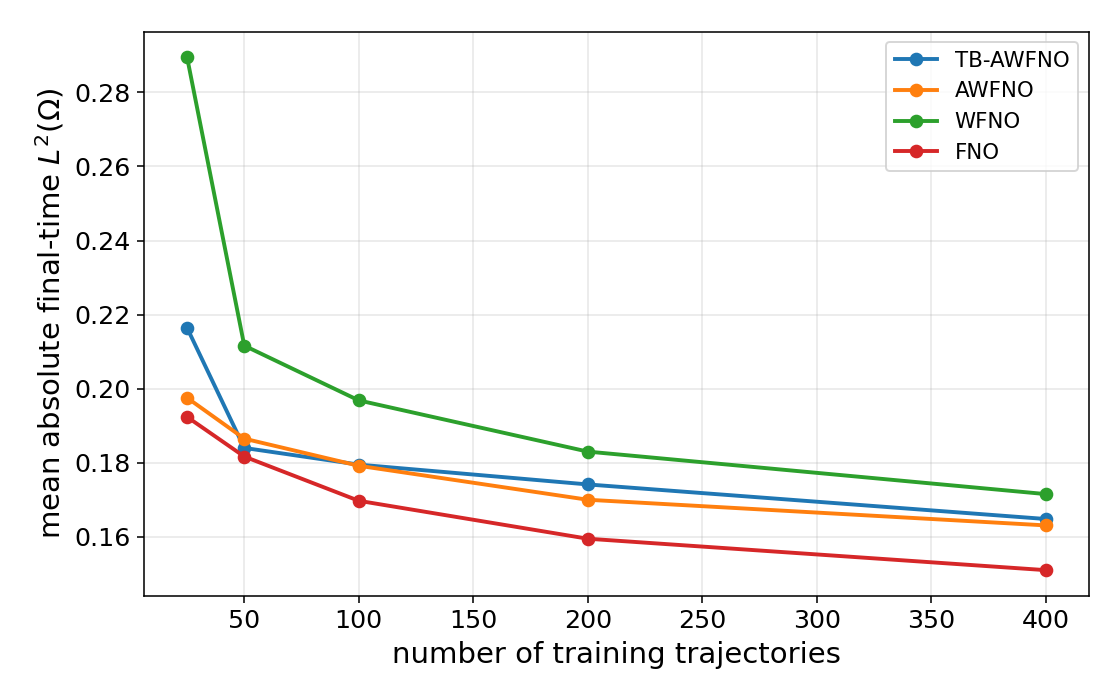

Plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/l2_error_per_timestep/all_tests_mean_median_L2_error_6d34680f95.png


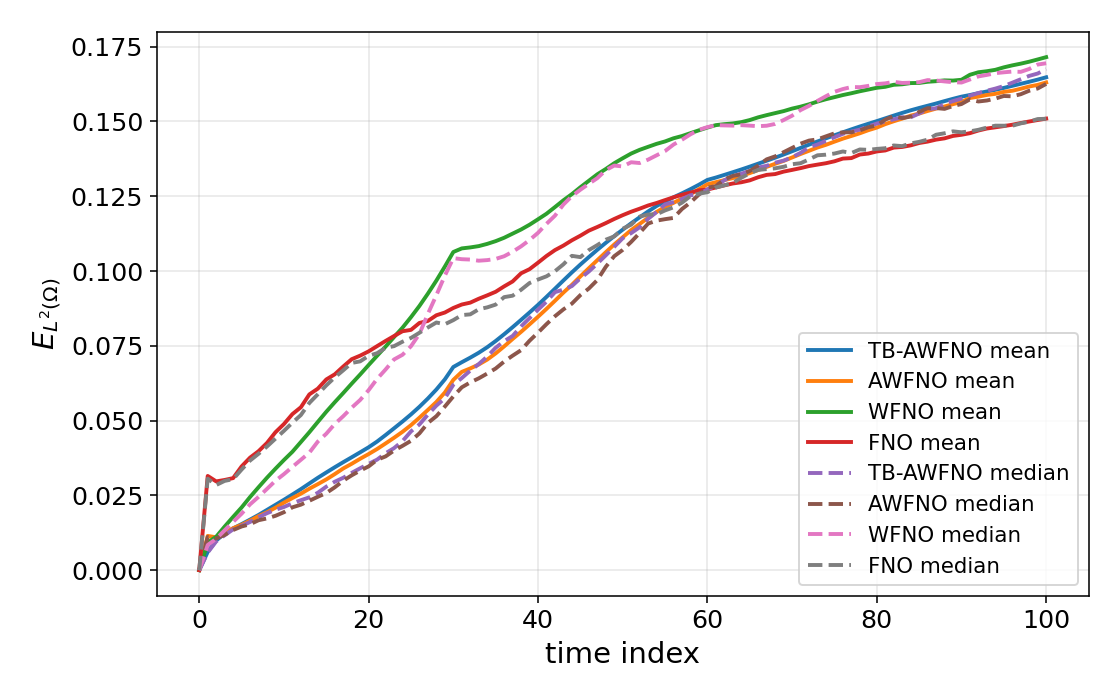

Plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/selected_test_case_annulus/test_005_annulus_fields_6d34680f95.png


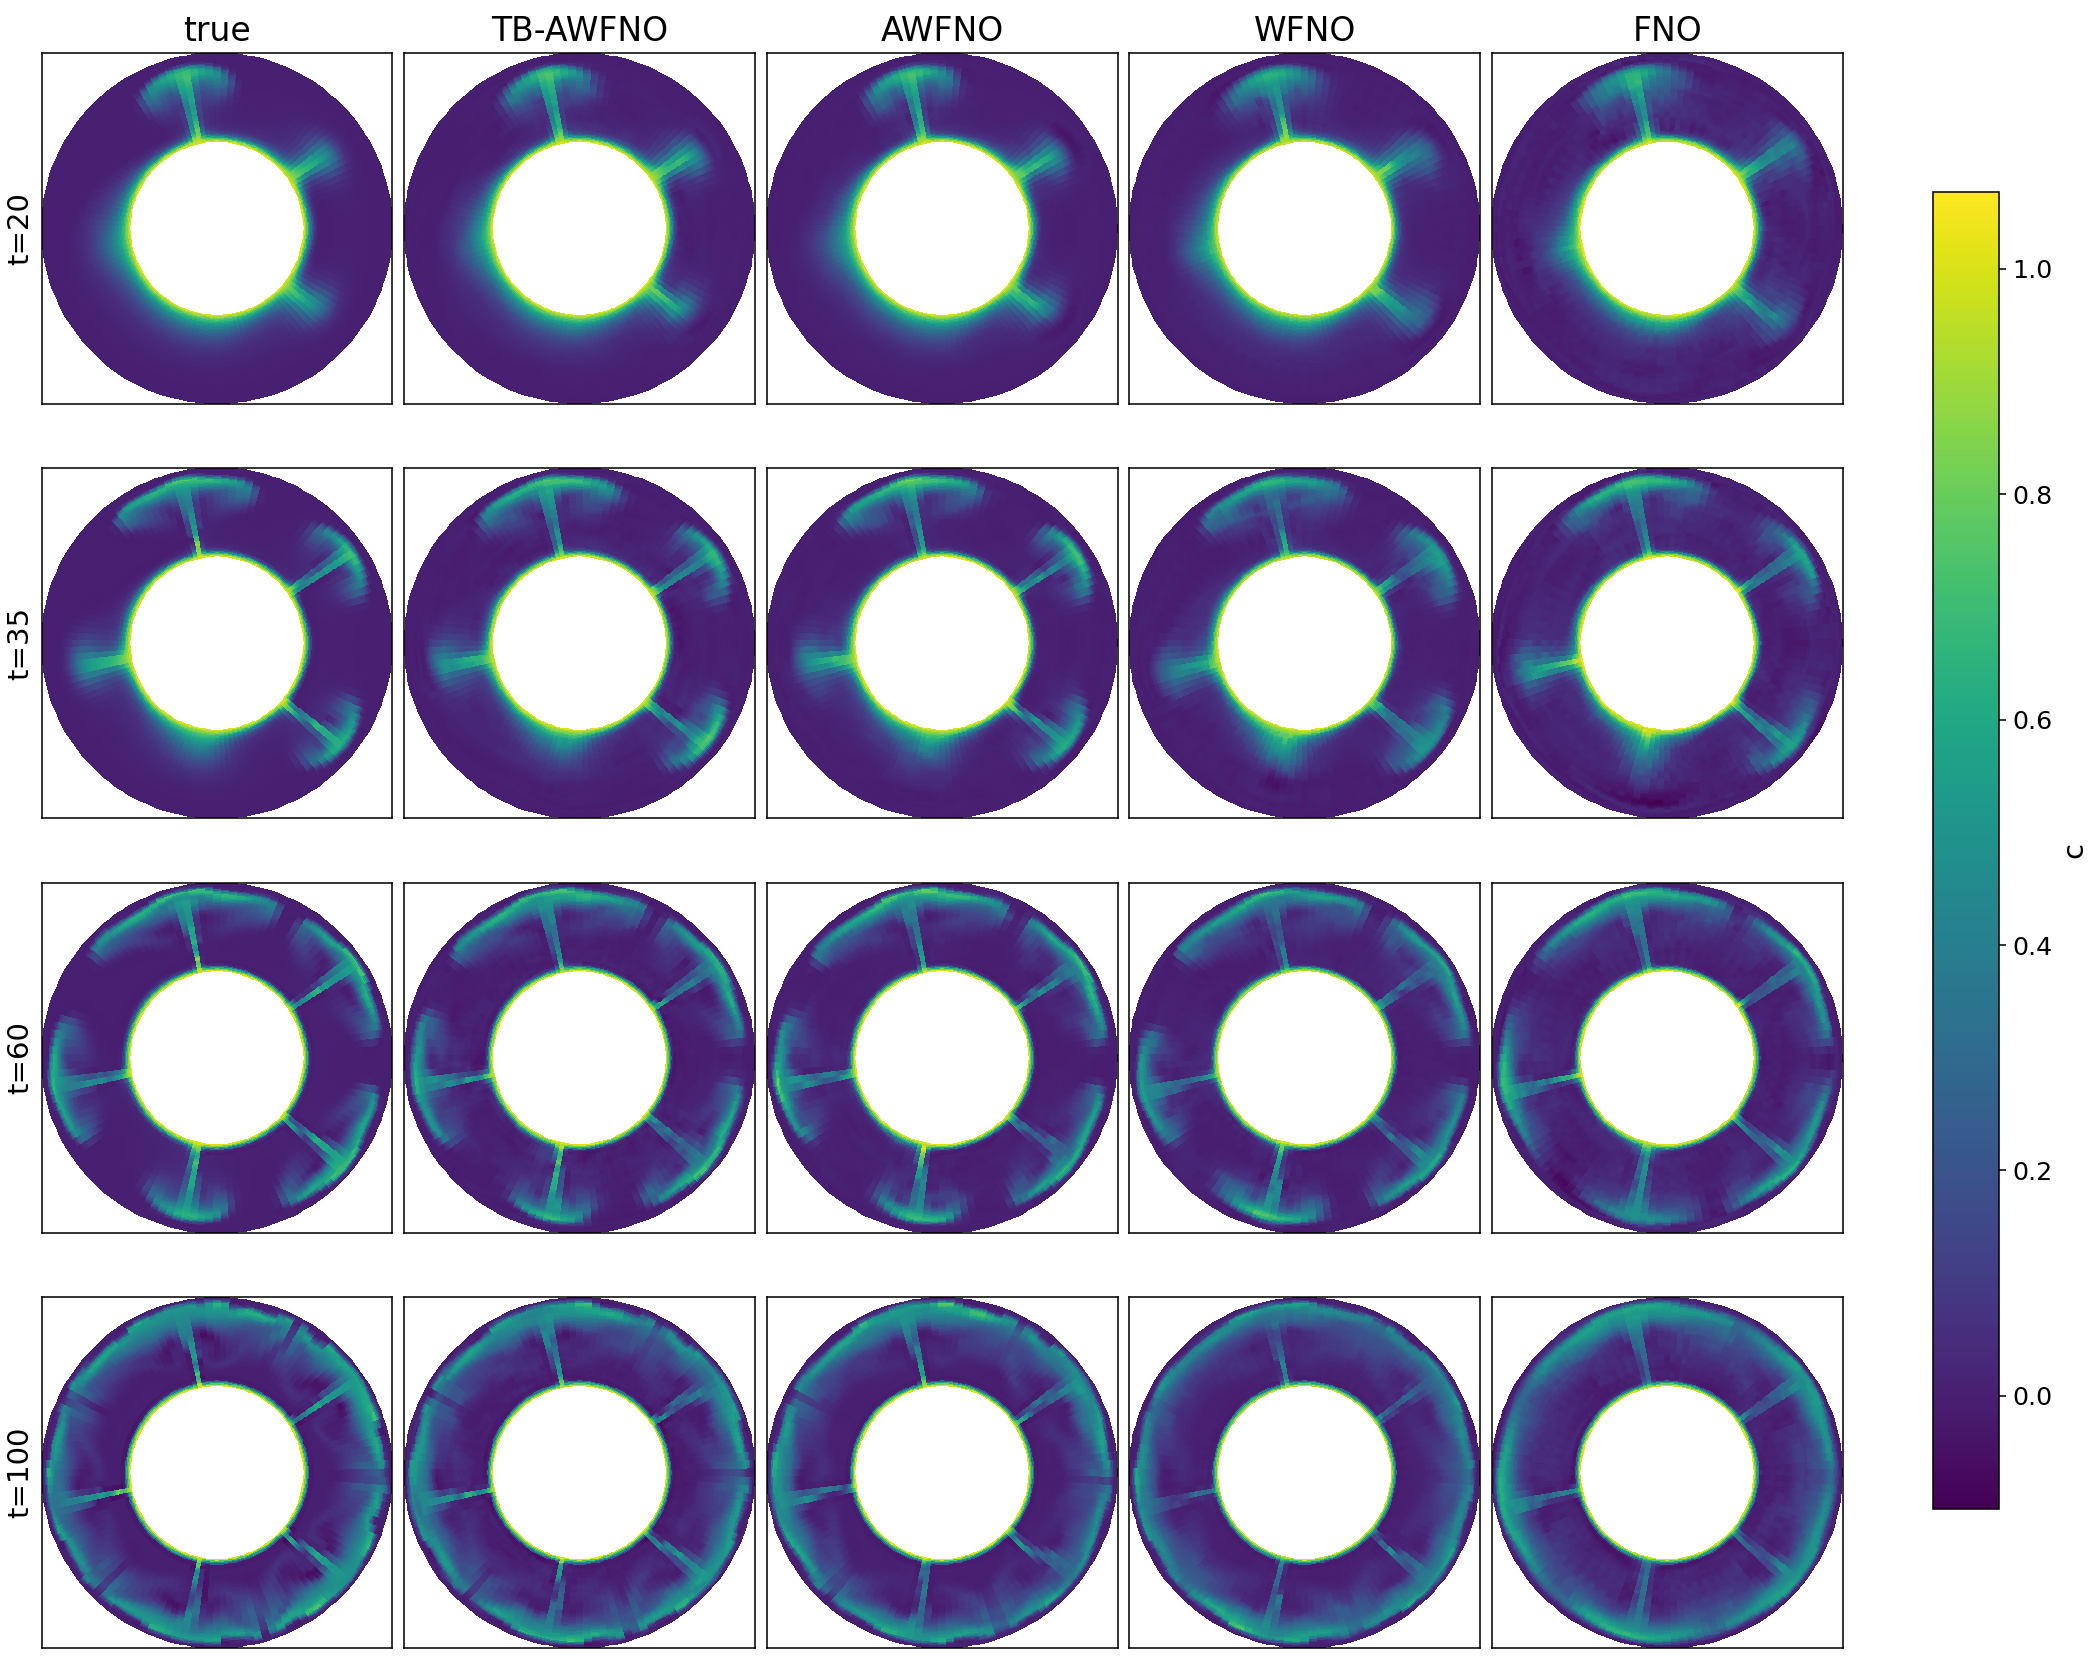

\nSTART: rebuttal | driver=/content/annulus2d_jcp_experiments.py | output=/content/gdrive/MyDrive/anus/Boussinesq_JCP
Live training output will appear below. Full log: /content/gdrive/MyDrive/anus/Boussinesq_JCP/rebuttal_stdout.log
Using device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition

Loaded annulus data
-------------------
file: /content/gdrive/MyDrive/anus/hyteg_annulus_c_grid_64x128_samples500.pt
U                       : shape=(500, 64, 128, 101), dtype=float32, memory=1.541 GB
r shape: (64,)
theta shape: (128,)
t shape: (101,)
U min/max: -0.13059653341770172 1.0094236135482788

Geometry
--------
N, Nr, Ntheta, Nt: 500 64 128 101
r range          : 0.5 1.0
theta range      : 0.0 6.234097957611084
DR               : 0.007936507936507936
DTHETA           : 0.04908738521234052
DT_SNAPSHOT      : 1.0

Data split
----------
split mode       : contiguous
U_train_pool     : (400, 64, 128, 101)
U_val            : (30, 64, 128, 101)
U_test           : (70, 64, 128, 101)
trai

In [5]:
#@title 5. Run each selected suite (Drive checkpoints allow resumption)
cfg=os.environ.copy()
cfg.update({
  'DATA_PATH':str(DATASET),'OUTPUT_ROOT':str(OUTPUT_ROOT),
  'RUN_SAMPLE_SIZES':SAMPLE_SIZES,
  'EPOCHS':str(EPOCHS),'BATCH_SIZE':str(BATCH_SIZE),
  'SPLIT_MODE':'contiguous','SPLIT_SEED':'2026',
  'N_VAL':'30','N_TEST':'70',
  'WINDOW_K':'30','WINDOW_STRIDE':'30','N_TIME_MODES':'18',
  'WIDTH':'32','N_LAYERS':'4','MODES_R':'16','MODES_THETA':'24',
  'LOCAL_RADIUS':'2',
  'REBUTTAL_N_TRAIN':str(N_TRAIN_CONTROLLED),
  'REBUTTAL_SEEDS':SEEDS,'REBUTTAL_RUN':CONTROLLED_SUITE,
  'REBUTTAL_OUTPUT':str(OUTPUT_ROOT/'jcp_controlled_annulus'),
  'WINDOW_SWEEP':WINDOW_SWEEP,'RADIUS_SWEEP':RADIUS_SWEEP,
  'FORCE_RETRAIN':'1' if FORCE_RETRAIN else '0','PYTHONUNBUFFERED':'1'
})
# Stream child process logs to Colab and save them on Drive.
# A heartbeat continues even during slow model-library imports or data loading.
from threading import Event, Thread
from IPython.display import display, Image, Markdown

def preview_saved_plots():
    # Show the newest sample-size and per-time error plots in Colab.
    patterns = ['sample_size_sweep_abs_full_L2*.png',
                'sample_size_sweep_abs_final_L2*.png',
                'all_tests_mean_median_L2_error_*.png',
                '*_annulus_fields*.png']
    for pat in patterns:
        candidates=list(OUTPUT_ROOT.rglob(pat))
        if candidates:
            figure=max(candidates,key=lambda p:p.stat().st_mtime)
            print('Plot:',figure,flush=True)
            display(Image(filename=str(figure), width=850))

for stage, enabled in [('original', RUN_ORIGINAL), ('rebuttal', RUN_CONTROLLED)]:
    if not enabled:
        continue
    env=dict(cfg)
    env['EXPERIMENT_SUITE']=stage
    log_path=OUTPUT_ROOT / f'{stage}_stdout.log'
    print(f'\\nSTART: {stage} | driver={DRIVER} | output={OUTPUT_ROOT}',flush=True)
    print(f'Live training output will appear below. Full log: {log_path}',flush=True)
    done=Event()

    def heartbeat():
        while not done.wait(45):
            print(f'[{stage}] subprocess is still running; checking for training output...',flush=True)

    watcher=Thread(target=heartbeat,daemon=True)
    watcher.start()
    try:
        with log_path.open('a',encoding='utf-8') as log:
            with subprocess.Popen(
                [sys.executable,'-u',str(DRIVER)],
                env=env,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                text=True,bufsize=1
            ) as proc:
                for line in proc.stdout:
                    print(line,end='',flush=True)
                    log.write(line)
                    log.flush()
                exit_status=proc.wait()
            if exit_status != 0:
                raise subprocess.CalledProcessError(exit_status,[sys.executable,str(DRIVER)])
    finally:
        done.set()
        watcher.join()
    print('DONE:',stage,flush=True)
    if stage == 'original':
        preview_saved_plots()
print('Finished all selected stages. Results:',OUTPUT_ROOT)

## Saved summaries

The final cell is safe to rerun independently after interrupted training. It displays completed summaries only and calculates mean/standard deviation across available controlled seeds (not across sample sizes).

In [6]:
#@title 6. Aggregate available experimental results
import json
import pandas as pd
from IPython.display import display
for source in sorted(OUTPUT_ROOT.rglob('sample_size_sweep_summary_run_*.json')):
    print('Original sample-size results:',source)
    display(pd.DataFrame(json.loads(source.read_text())))
p=OUTPUT_ROOT/'jcp_controlled_annulus'/'results.csv'
if p.exists():
    raw=pd.read_csv(p)
    print('Controlled trials:',len(raw))
    display(raw.head(10))
    metrics=[x for x in ['full_l2_mean','final_l2_mean','low_theta_l2','high_theta_l2','sharp_region_l2','train_seconds','rollout_seconds','numel_parameters','real_scalar_dof','peak_rollout_gpu_MiB'] if x in raw.columns]
    agg=raw.groupby('experiment',as_index=False)[metrics].agg(['mean','std'])
    agg.columns=['_'.join(filter(None,map(str,col))) for col in agg.columns.to_flat_index()]
    out=p.parent/'results_aggregated_by_seed.csv'
    agg.to_csv(out,index=False)
    print('Aggregated:',out)
    display(agg)
else:
    print('Controlled trials not started:',p)

Original sample-size results: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/results/sample_size_sweep_summary_run_25-50-100-200-400.json


,N_train,winner,TB_AWFNO_full_l2_mean,AWFNO_full_l2_mean,WFNO_full_l2_mean,FNO_full_l2_mean,TB_AWFNO_final_l2_mean,AWFNO_final_l2_mean,WFNO_final_l2_mean,FNO_final_l2_mean,...,FNO_real_scalar_dof,FNO_full_test_set_inference_seconds,FNO_amortized_inference_seconds_per_test_trajectory,FNO_peak_rollout_gpu_MiB,FNO_low_theta_l2,FNO_high_theta_l2,FNO_sharp_region_l2,FNO_sharp_region_spatial_fraction,FNO_theta_frequency_cutoff,FNO_sharp_truth_gradient_quantile
0,25,AWFNO,1.972765,1.758546,2.156654,1.976758,0.216423,0.197526,0.289536,0.192357,...,1723716,0.830210,0.011860,585.370605,1.600421,1.155889,0.552242,0.100098,12,0.9
1,50,AWFNO,1.560176,1.542665,1.840804,1.773958,0.183970,0.186475,0.211597,0.181639,...,1723716,0.102420,0.001463,491.955078,1.343284,1.153961,0.516284,0.100098,12,0.9
2,100,AWFNO,1.389734,1.370440,1.661229,1.487443,0.179464,0.179151,0.196812,0.169689,...,1723716,0.108993,0.001557,491.955078,1.002216,1.094511,0.435621,0.100098,12,0.9
3,200,AWFNO,1.251364,1.221884,1.448420,1.298232,0.174108,0.169972,0.182979,0.159445,...,1723716,0.102402,0.001463,491.955078,0.857453,0.970834,0.370060,0.100098,12,0.9
4,400,AWFNO,1.126228,1.106069,1.285439,1.132538,0.164774,0.163045,0.171504,0.150958,...,1723716,0.104395,0.001491,491.955078,0.719484,0.870719,0.316939,0.100098,12,0.9


Controlled trials: 54


,experiment,seed,n_train,architecture,K,stride,radius,modes_r,modes_theta,n_time_modes,...,train_seconds,rollout_seconds,peak_rollout_gpu_MiB,best_val_l2,low_theta_l2,high_theta_l2,sharp_region_l2,sharp_region_spatial_fraction,theta_frequency_cutoff,sharp_truth_gradient_quantile
0,ordering_LGL,1234,400,"{""family"": ""composed"", ""order"": ""LGL""}",30,30,2,16,24,18,...,109.691980,0.186139,1934.216797,0.264889,0.663672,0.904139,0.299842,0.100098,12,0.9
1,ordering_LGL,1235,400,"{""family"": ""composed"", ""order"": ""LGL""}",30,30,2,16,24,18,...,108.558685,0.148077,697.794922,0.267362,0.677681,0.907658,0.302868,0.100098,12,0.9
2,ordering_LGL,1236,400,"{""family"": ""composed"", ""order"": ""LGL""}",30,30,2,16,24,18,...,107.904253,0.147594,695.794922,0.272562,0.661256,0.894468,0.295300,0.100098,12,0.9
3,ordering_LLG,1234,400,"{""family"": ""composed"", ""order"": ""LLG""}",30,30,2,16,24,18,...,107.953347,0.148680,696.576172,0.266406,0.659905,0.893254,0.299975,0.100098,12,0.9
4,ordering_LLG,1235,400,"{""family"": ""composed"", ""order"": ""LLG""}",30,30,2,16,24,18,...,108.211481,0.147427,697.857422,0.264468,0.660810,0.897377,0.298779,0.100098,12,0.9
5,ordering_LLG,1236,400,"{""family"": ""composed"", ""order"": ""LLG""}",30,30,2,16,24,18,...,107.948804,0.149583,697.294922,0.276695,0.677205,0.911253,0.307047,0.100098,12,0.9
6,ordering_GLL,1234,400,"{""family"": ""composed"", ""order"": ""GLL""}",30,30,2,16,24,18,...,107.532405,0.147493,699.076172,0.266731,0.650979,0.884593,0.296985,0.100098,12,0.9
7,ordering_GLL,1235,400,"{""family"": ""composed"", ""order"": ""GLL""}",30,30,2,16,24,18,...,107.368146,0.148252,695.794922,0.268258,0.667369,0.893754,0.295822,0.100098,12,0.9
8,ordering_GLL,1236,400,"{""family"": ""composed"", ""order"": ""GLL""}",30,30,2,16,24,18,...,107.893033,0.148414,695.794922,0.268865,0.666571,0.906023,0.300677,0.100098,12,0.9
9,component_LLL,1234,400,"{""family"": ""composed"", ""order"": ""LLL""}",30,30,2,16,24,18,...,116.577946,0.151523,647.580078,0.363497,1.203869,1.036609,0.437402,0.100098,12,0.9


Aggregated: /content/gdrive/MyDrive/anus/Boussinesq_JCP/jcp_controlled_annulus/results_aggregated_by_seed.csv


,experiment,full_l2_mean_mean,full_l2_mean_std,final_l2_mean_mean,final_l2_mean_std,low_theta_l2_mean,low_theta_l2_std,high_theta_l2_mean,high_theta_l2_std,sharp_region_l2_mean,...,train_seconds_mean,train_seconds_std,rollout_seconds_mean,rollout_seconds_std,numel_parameters_mean,numel_parameters_std,real_scalar_dof_mean,real_scalar_dof_std,peak_rollout_gpu_MiB_mean,peak_rollout_gpu_MiB_std
0,TB_AWFNO,1.132115,0.013640,0.165271,0.002749,0.679027,0.008349,0.900863,0.010464,0.301740,...,107.912876,0.504419,0.147606,0.001083,3357490.0,0.0,6503218.0,0.0,737.160645,1.000000
1,component_GGG,1.152547,0.004936,0.167220,0.000409,0.683598,0.003992,0.923460,0.002917,0.309493,...,91.933114,0.095169,0.140361,0.000929,9445438.0,0.0,18882622.0,0.0,795.432943,0.710780
2,component_LLL,1.576323,0.017541,0.204194,0.004252,1.186033,0.019485,1.030357,0.005433,0.437552,...,116.069763,0.441220,0.151972,0.000452,315838.0,0.0,315838.0,0.0,647.580078,0.000000
3,matched_AWFNO,1.127846,0.010270,0.166091,0.002453,0.666503,0.009570,0.905229,0.009668,0.299870,...,108.193112,0.482700,0.147822,0.000319,3359038.0,0.0,6504766.0,0.0,696.722005,0.810293
4,matched_WFNO,1.293488,0.021199,0.170677,0.002653,0.846780,0.013987,0.972517,0.015846,0.355563,...,50.097554,0.670297,0.132980,0.015640,3358283.0,0.0,6703691.0,0.0,769.772461,0.812158
5,modes_16_24,1.126052,0.009829,0.165902,0.002112,0.665973,0.010102,0.903382,0.007438,0.299525,...,107.633984,0.153861,0.147920,0.000335,3359038.0,0.0,6504766.0,0.0,696.628255,0.577350
6,modes_24_32,1.117662,0.007106,0.164693,0.001219,0.654440,0.008557,0.900388,0.003277,0.297933,...,111.901708,0.209006,0.149126,0.000910,6504766.0,0.0,12796222.0,0.0,743.076172,0.000000
7,modes_8_12,1.113942,0.010894,0.163407,0.001546,0.660829,0.009221,0.891345,0.006008,0.303727,...,107.433329,0.541489,0.147199,0.000900,999742.0,0.0,1786174.0,0.0,658.794922,0.000000
8,ordering_GLL,1.116675,0.013484,0.163542,0.001429,0.661640,0.009241,0.894790,0.010752,0.297828,...,107.597862,0.268496,0.148053,0.000491,3359038.0,0.0,6504766.0,0.0,696.888672,1.894431
9,ordering_LGL,1.125849,0.009920,0.165656,0.001824,0.667536,0.008868,0.902088,0.006830,0.299336,...,108.718306,0.904490,0.160603,0.022116,3359038.0,0.0,6504766.0,0.0,1109.268880,714.426552


Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/sample_size_sweep_abs_full_L2_common_test_run_25-50-100-200-400.png


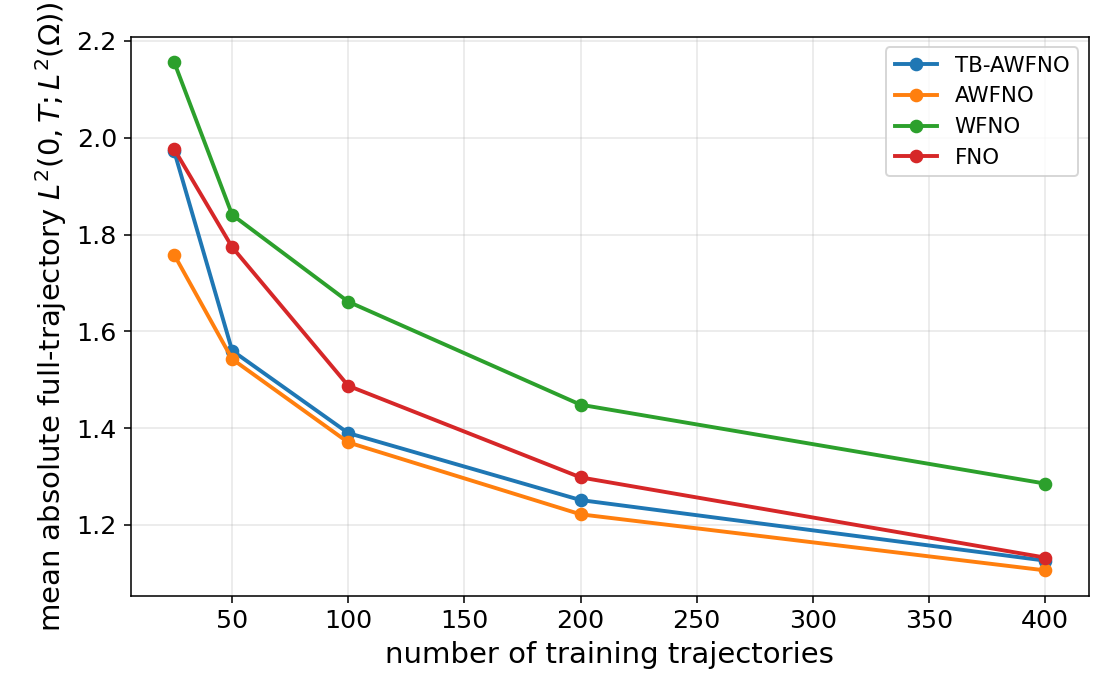

Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/sample_size_sweep_abs_final_L2_common_test_run_25-50-100-200-400.png


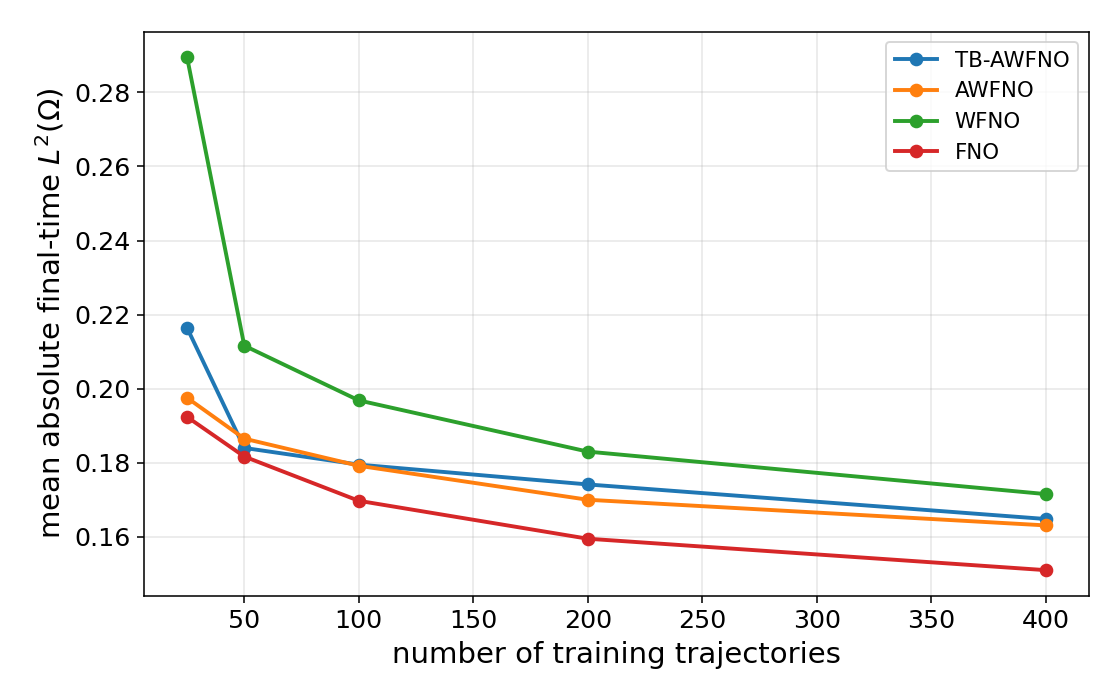

Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/l2_error_per_timestep/all_tests_mean_median_L2_error_6d34680f95.png


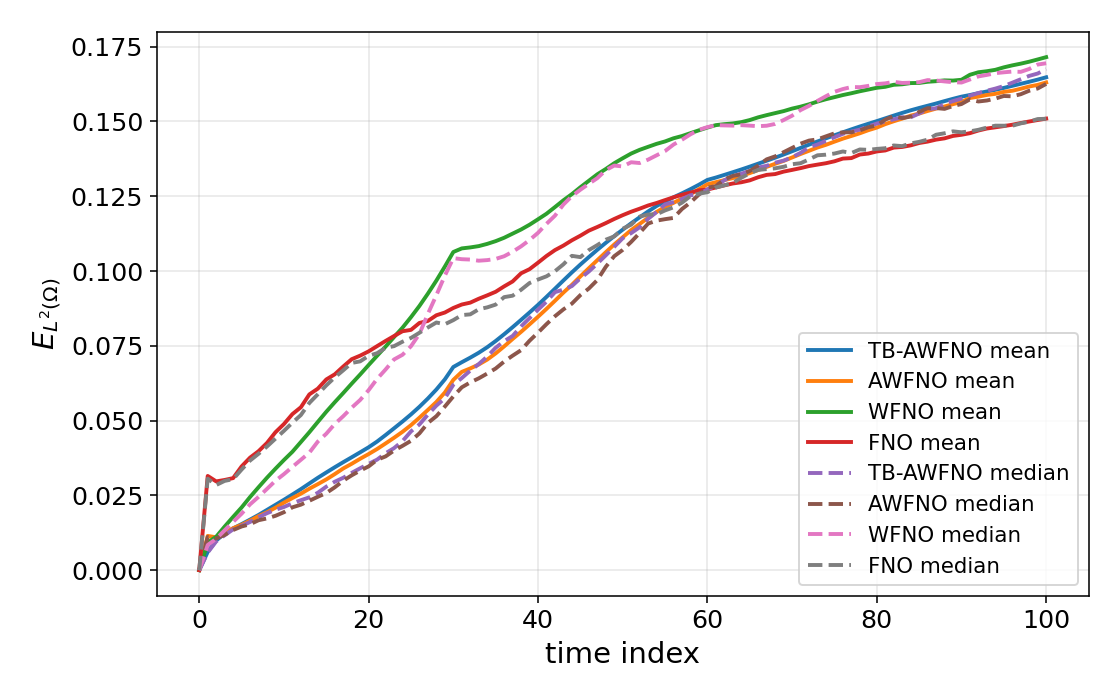

Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/selected_test_case_annulus/test_005_annulus_fields_6d34680f95.png


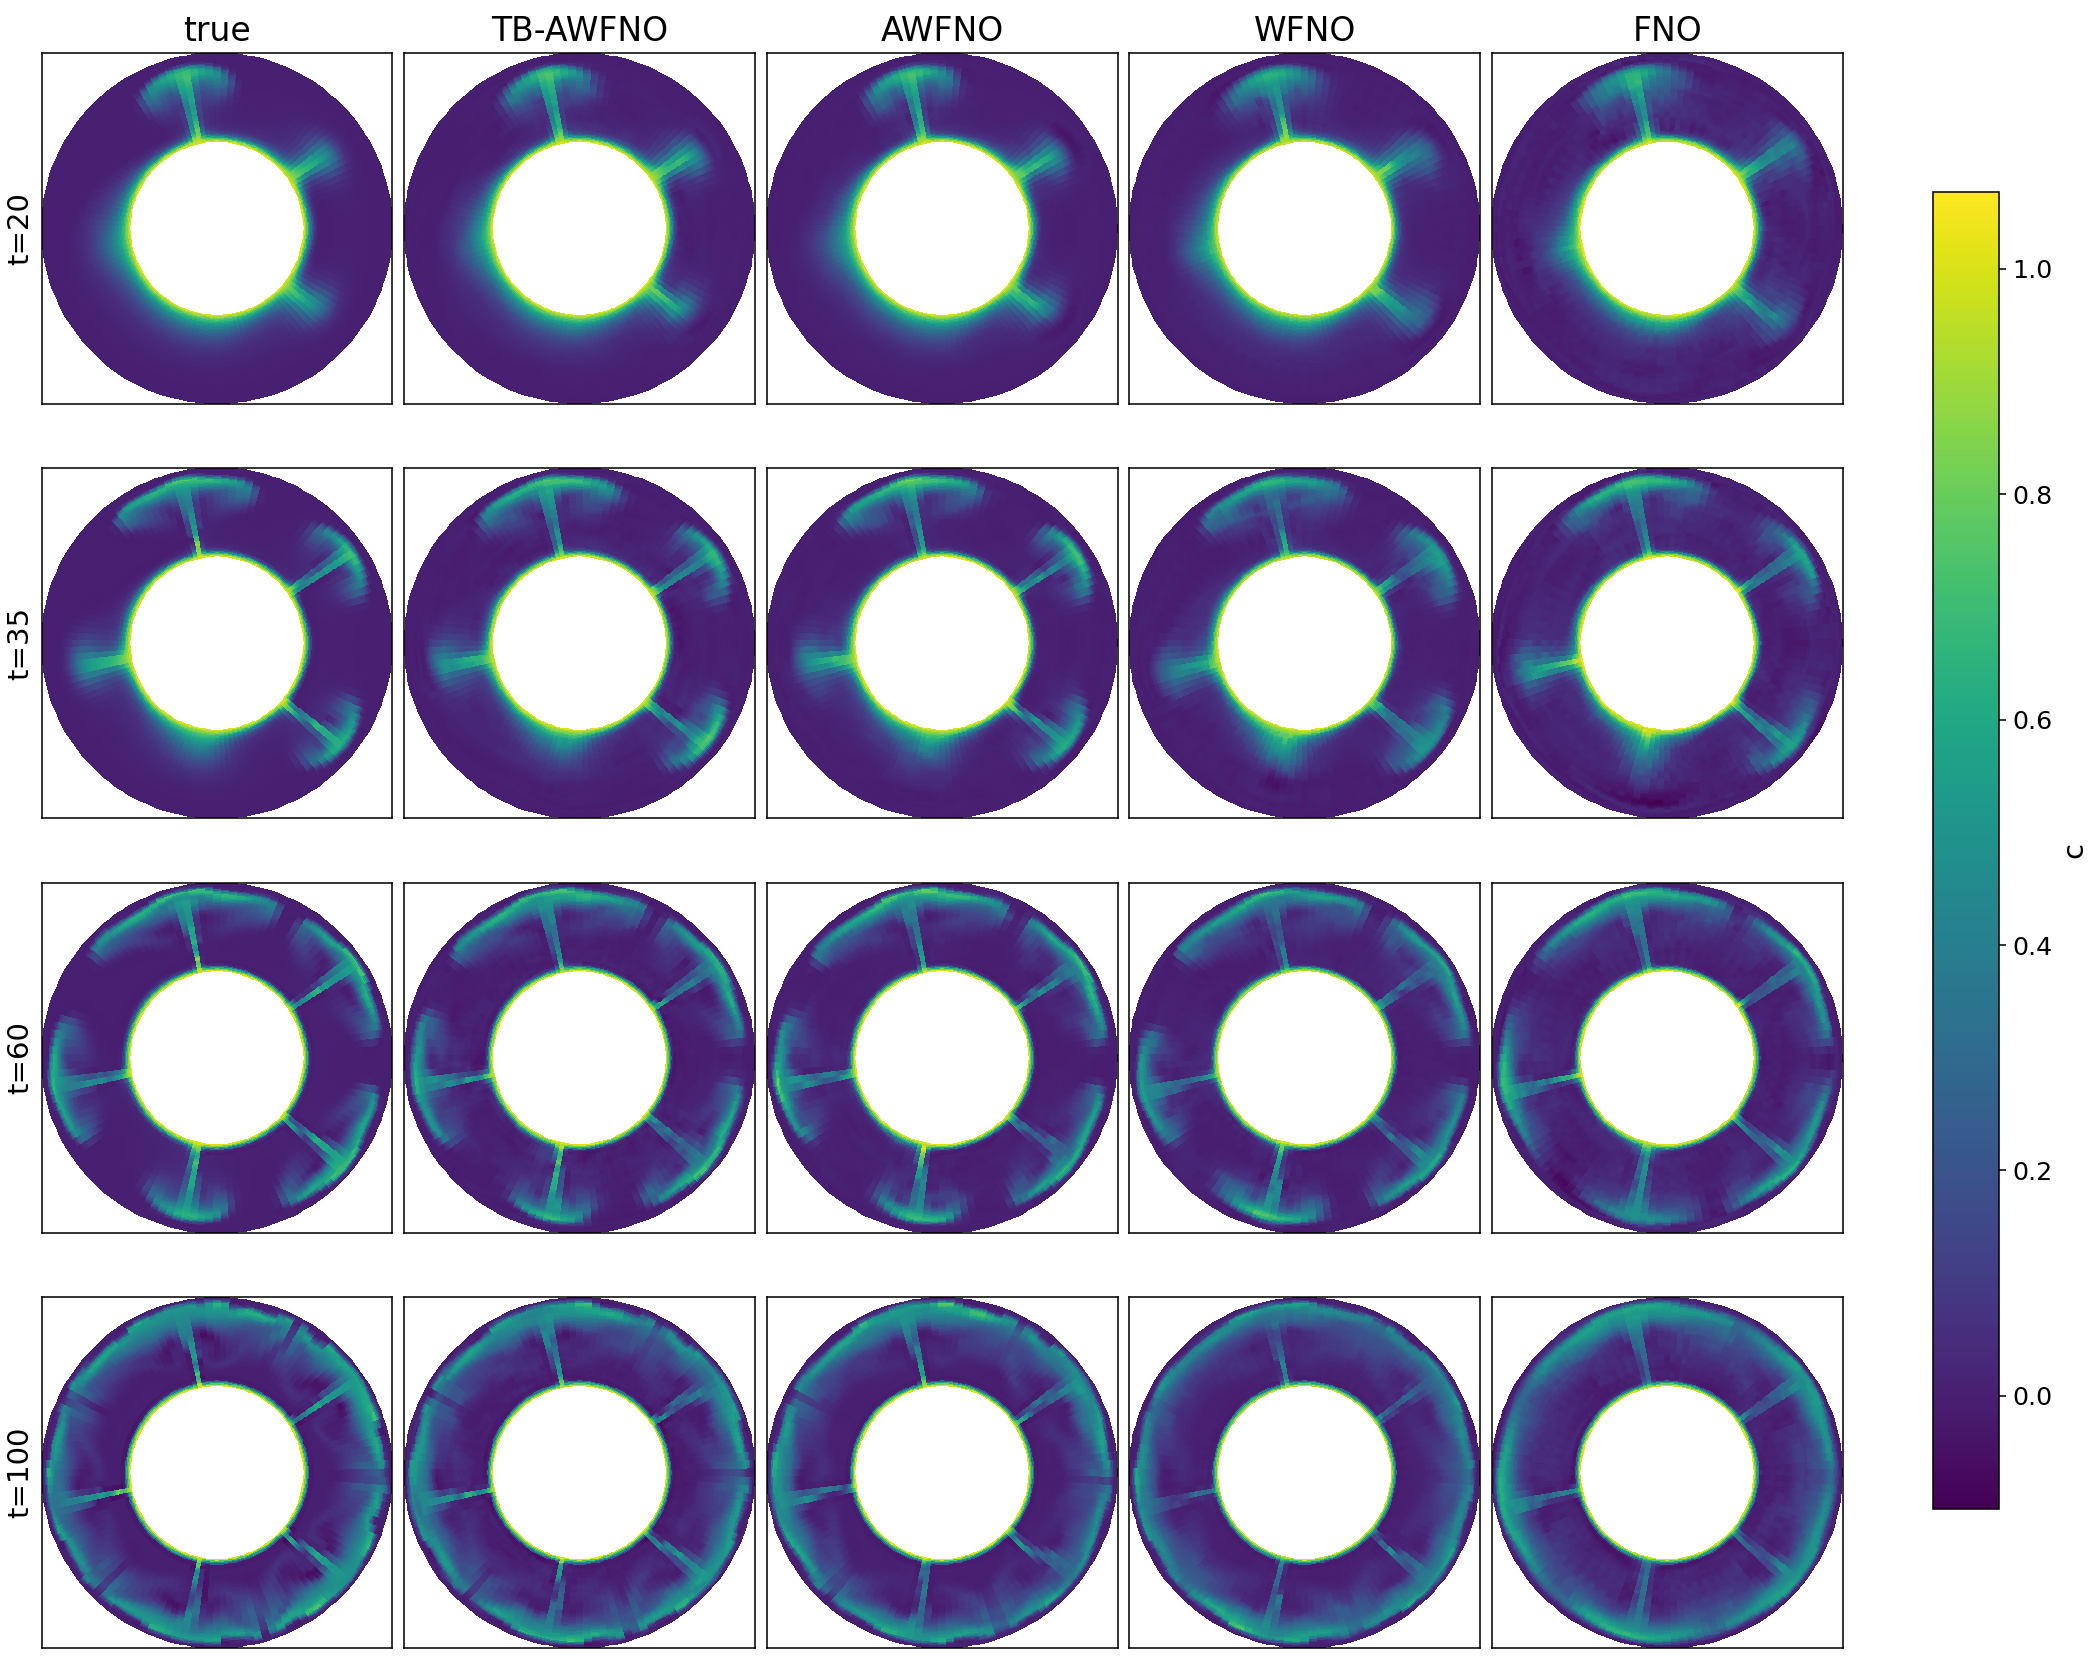

Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/best_worst_test_cases/best_1_test_005_6d34680f95.png


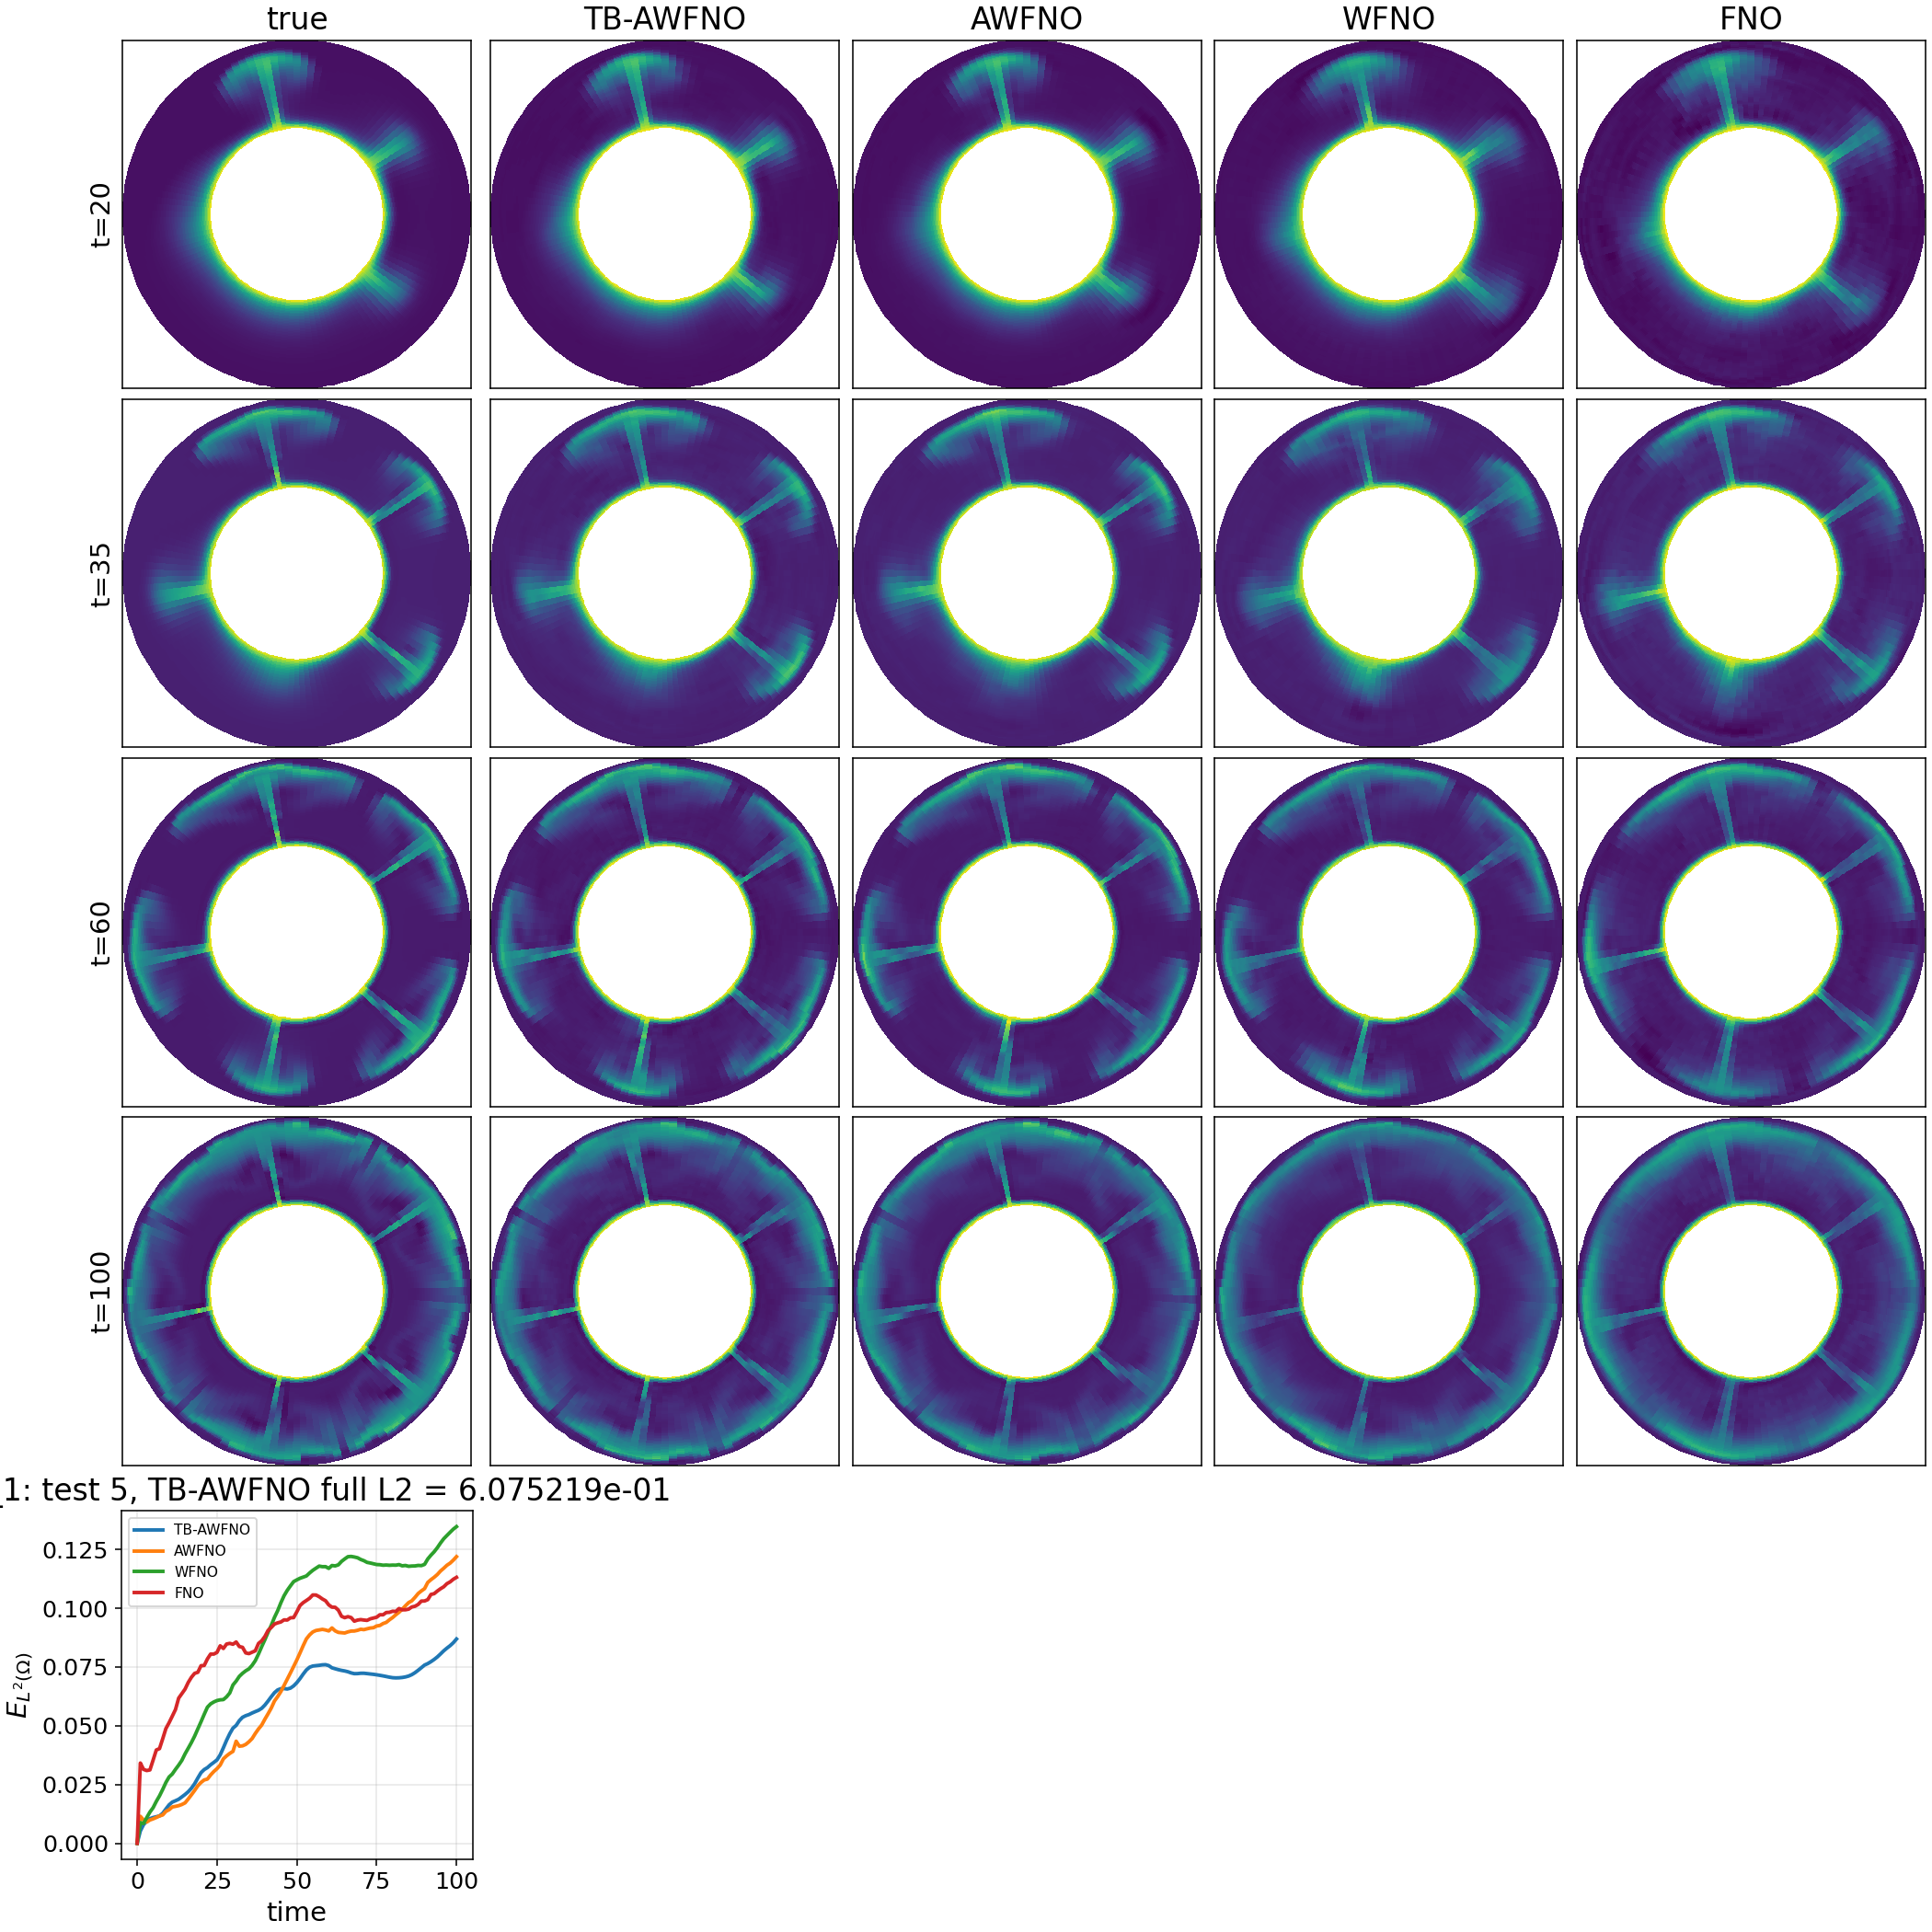

Saved plot: /content/gdrive/MyDrive/anus/Boussinesq_JCP/cache_annulus2d_awfno_sample_sweep_sizes25-50-100-200-400_K30_M18_W32_mr16_mt24_R2/plots/best_worst_test_cases/worst_1_test_002_6d34680f95.png


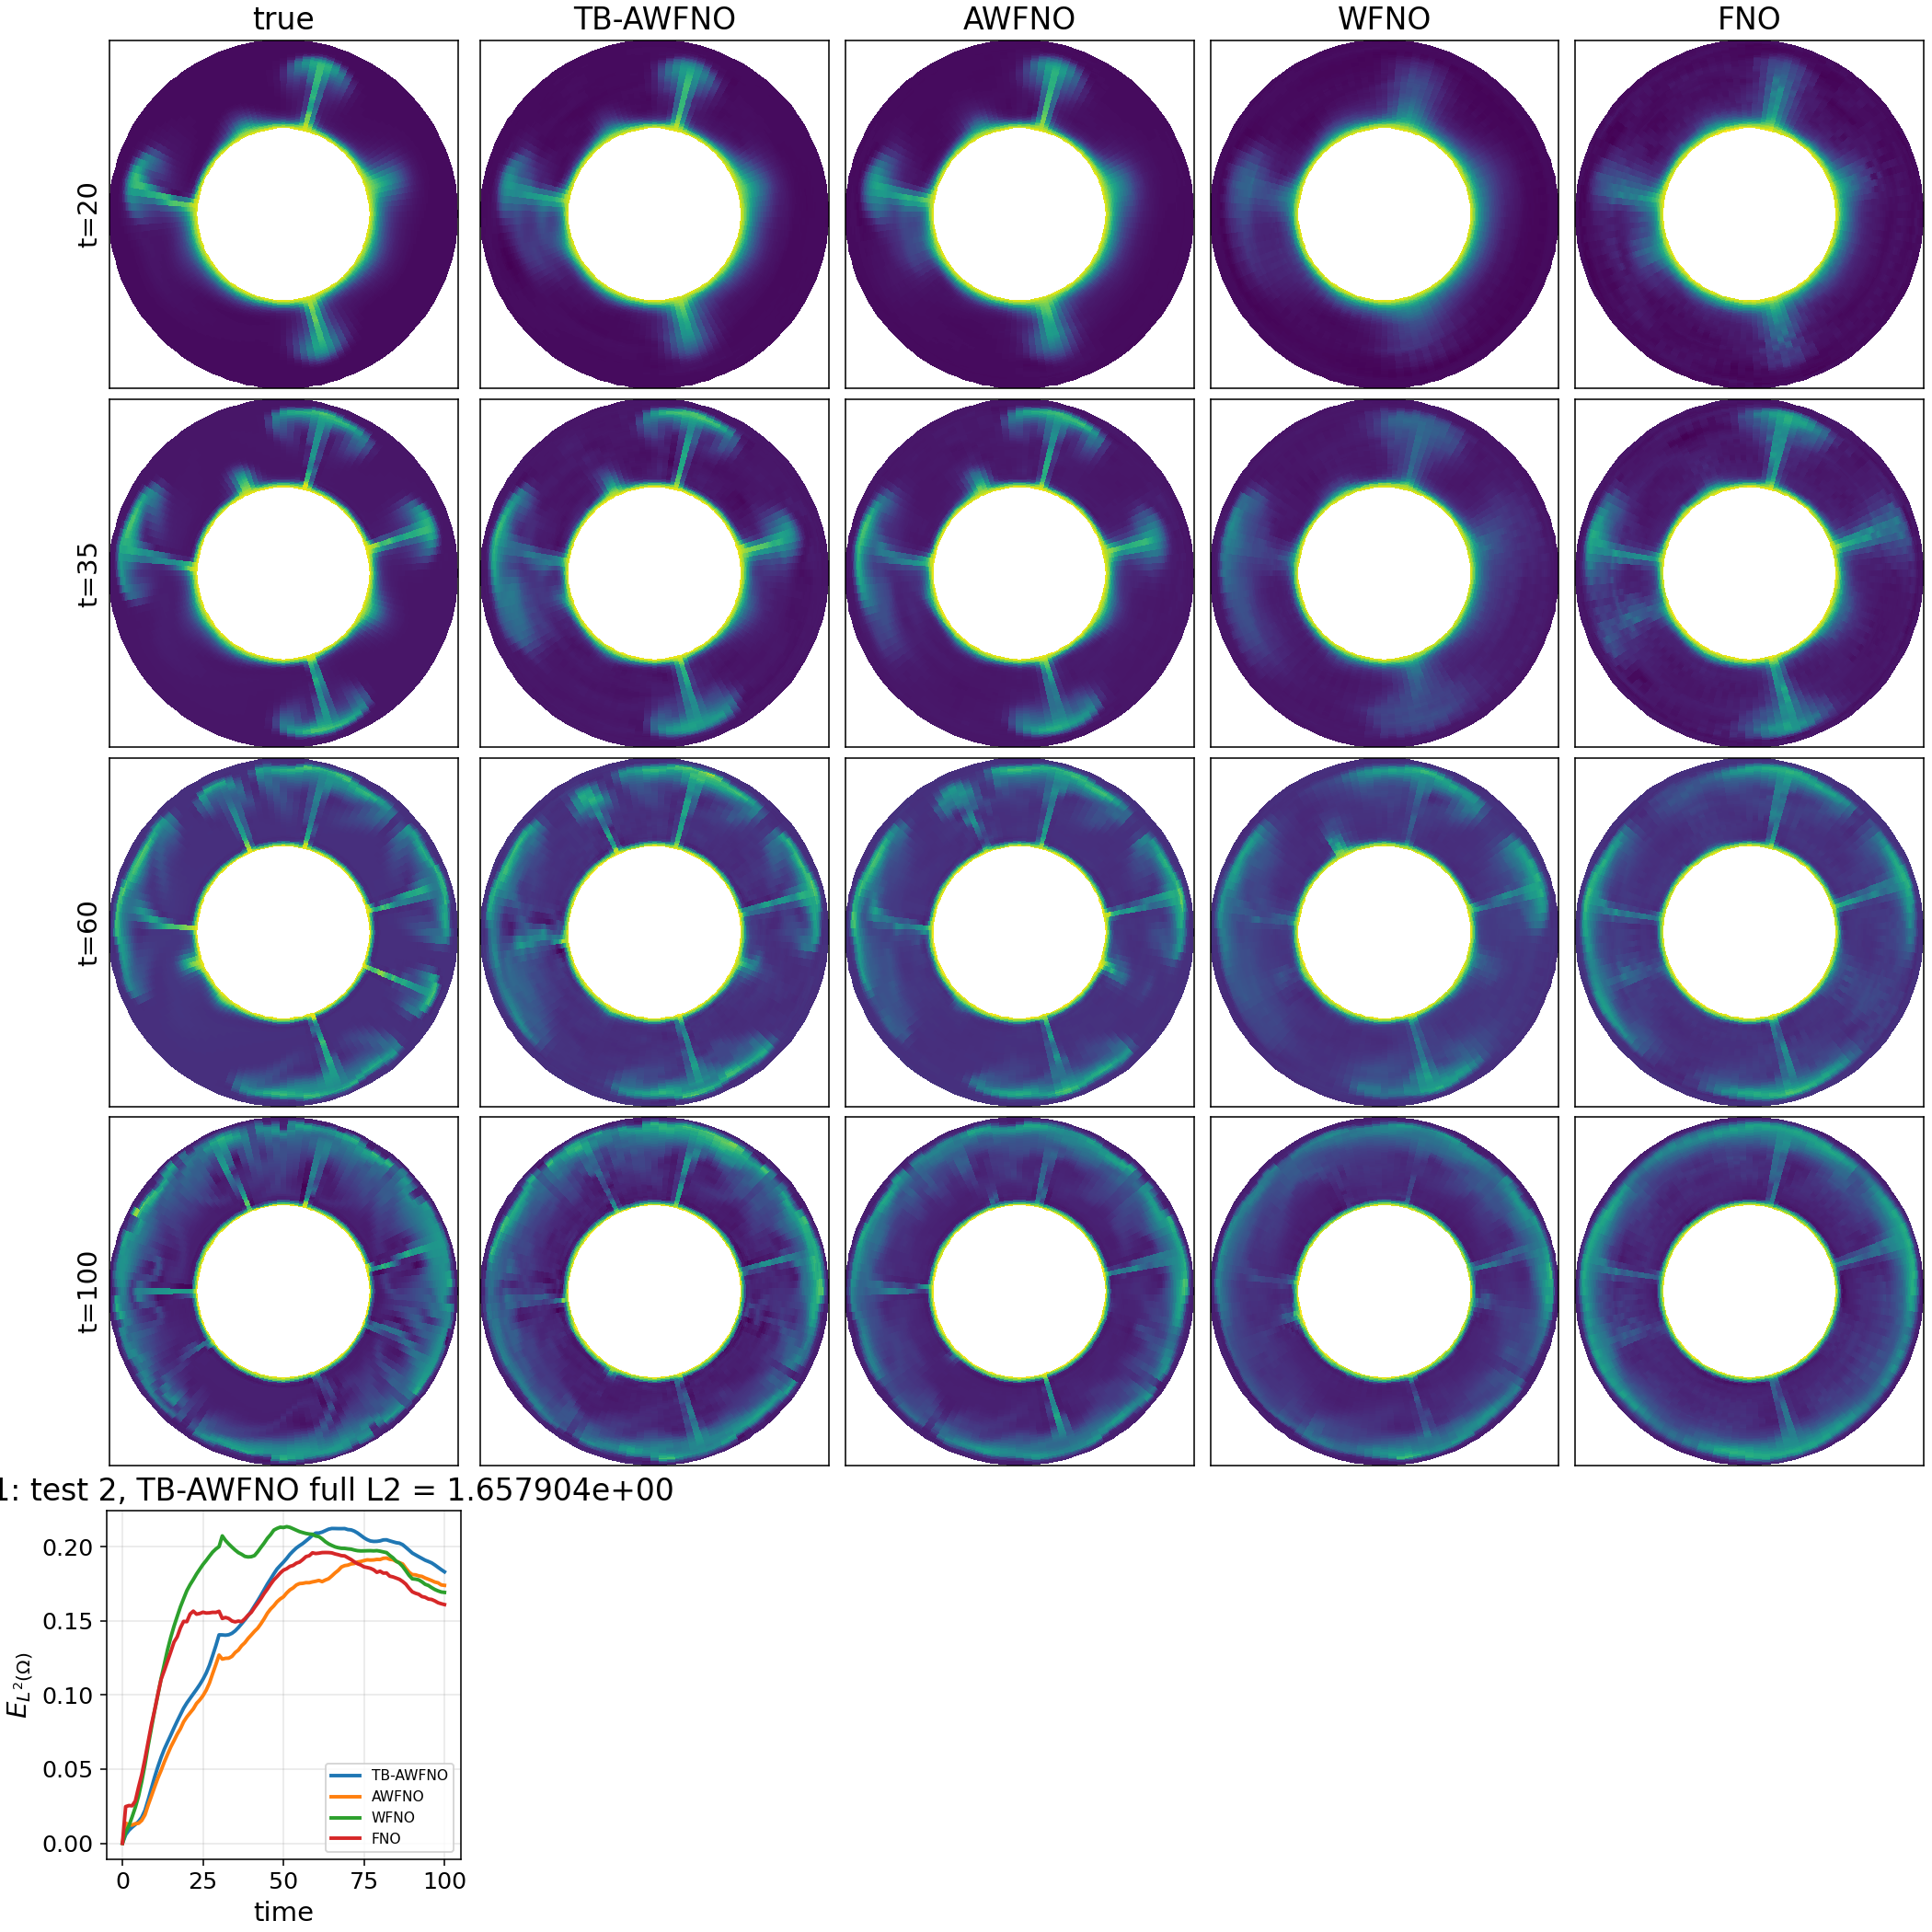

All PNG files: 280


In [7]:
#@title 7. View already saved figures (safe after stopping an interrupted run)
from pathlib import Path
from IPython.display import display, Image
root=Path('/content/gdrive/MyDrive/anus/Boussinesq_JCP')
patterns=['sample_size_sweep_abs_full_L2*.png',
          'sample_size_sweep_abs_final_L2*.png',
          'all_tests_mean_median_L2_error_*.png',
          '*_annulus_fields*.png',
          'best_1_test_*.png',
          'worst_1_test_*.png']
for pattern in patterns:
    matches=list(root.rglob(pattern))
    if matches:
        p=max(matches,key=lambda p:p.stat().st_mtime)
        print('Saved plot:',p)
        display(Image(filename=str(p),width=850))
    else:
        print('Not yet saved:',pattern)
print('All PNG files:',len(list(root.rglob('*.png'))))

In [8]:
# Disconnect and terminate the Colab runtime after all experiments finish
from google.colab import runtime

print("All experiments completed. Shutting down Colab runtime...")
runtime.unassign()

All experiments completed. Shutting down Colab runtime...
